In [ ]:
#  CELL 1: Install packages
!pip install -q peft==0.12.0 evaluate rouge-score nltk
print('Installation complete')

Installation complete


In [ ]:
# CELL 2: ALL imports + ALL datasets
import os, warnings, math
warnings.filterwarnings('ignore')

import torch
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

import transformers
print(f' transformers : {transformers.__version__}')
print(f' numpy        : {np.__version__}')
print(f' torch        : {torch.__version__}')

from datasets import load_dataset, Dataset as HFDataset
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    AutoModelForCausalLM,
    TrainingArguments,
    Trainer,
    DataCollatorWithPadding,
    DataCollatorForLanguageModeling,
    set_seed,
)
from peft import LoraConfig, get_peft_model, TaskType
import evaluate
import nltk
from nltk.translate.bleu_score import corpus_bleu, SmoothingFunction
nltk.download('punkt',     quiet=True)
nltk.download('punkt_tab', quiet=True)
set_seed(42)

# Plot colours
C = ['#2C7BB6', '#D7191C', '#1A9641', '#FDAE61']

#  GPU check
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
if torch.cuda.is_available():
    print(f' GPU  : {torch.cuda.get_device_name(0)}')
    print(f' VRAM : {torch.cuda.get_device_properties(0).total_memory/1e9:.1f} GB')
else:
    print(' NO GPU — go to Runtime > Change runtime type > A100 GPU')

#  Load AG News (120,000 train / 7,600 test / 4 balanced classes)
print('\nLoading AG News dataset...')
ag          = load_dataset('fancyzhx/ag_news')
ag_train    = ag['train']
ag_test     = ag['test']
LABEL_NAMES = ['World', 'Sports', 'Business', 'Sci/Tech']
NUM_LABELS  = 4
print(f' AG News loaded  — Train: {len(ag_train):,} | Test: {len(ag_test):,}')

# Load PersonaChat (17,878 train / 1,000 validation)
print('Loading PersonaChat dataset...')
pc         = load_dataset('AlekseyKorshuk/persona-chat')
pc_train   = pc['train']
pc_valid   = pc['validation']
print(f' PersonaChat loaded — Train: {len(pc_train):,} | Valid: {len(pc_valid):,}')

print('\n ALL SETUP COMPLETE — ready to train')

 transformers : 5.0.0
 numpy        : 2.0.2
 torch        : 2.10.0+cu128
 GPU  : Tesla T4
 VRAM : 15.6 GB

Loading AG News dataset...


README.md: 0.00B [00:00, ?B/s]

data/train-00000-of-00001.parquet:   0%|          | 0.00/18.6M [00:00<?, ?B/s]

data/test-00000-of-00001.parquet:   0%|          | 0.00/1.23M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/120000 [00:00<?, ? examples/s]

...

data/train-00000-of-00001.parquet:   0%|          | 0.00/97.5M [00:00<?, ?B/s]

data/validation-00000-of-00001.parquet:   0%|          | 0.00/4.82M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/17878 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/1000 [00:00<?, ? examples/s]

 PersonaChat loaded — Train: 17,878 | Valid: 1,000

 ALL SETUP COMPLETE — ready to train


In [ ]:
#  CELL 3: Exploratory Data Analysis
# AG News
tr_c  = [ag_train['label'].count(i) for i in range(4)]
te_c  = [ag_test['label'].count(i)  for i in range(4)]
tlen  = [len(t.split()) for t in ag_train['text'][:5000]]

# PersonaChat
pl, tc, rl = [], [], []
for row in pc_train:
    pl.append(len(row['personality']))
    tc.append(len(row['utterances']))
    for u in row['utterances']:
        if u['candidates']:
            rl.append(len(u['candidates'][-1].split()))

fig = plt.figure(figsize=(18, 8))
fig.suptitle('Dataset EDA — AG News (top) and PersonaChat (bottom)',
             fontsize=14, fontweight='bold')
gs = gridspec.GridSpec(2, 3, figure=fig)

ax0 = fig.add_subplot(gs[0,0])
ax0.bar(LABEL_NAMES, tr_c, color=C)
ax0.set_title('AG News Train Labels')
ax0.set_ylabel('Count')
for i,v in enumerate(tr_c): ax0.text(i, v+200, f'{v:,}', ha='center', fontsize=9)

ax1 = fig.add_subplot(gs[0,1])
ax1.bar(LABEL_NAMES, te_c, color=C)
ax1.set_title('AG News Test Labels')
for i,v in enumerate(te_c): ax1.text(i, v+10, f'{v:,}', ha='center', fontsize=9)

ax2 = fig.add_subplot(gs[0,2])
ax2.hist(tlen, bins=40, color='#2C7BB6', edgecolor='white')
ax2.axvline(np.mean(tlen), color='red', ls='--', lw=2,
            label=f'Mean={np.mean(tlen):.0f}')
ax2.set_title('AG News Text Length')
ax2.set_xlabel('Words')
ax2.legend()

ax3 = fig.add_subplot(gs[1,0])
ax3.hist(pl, bins=10, color='#D7191C', edgecolor='white')
ax3.set_title('PersonaChat: Persona Statements')
ax3.set_xlabel('Count')

ax4 = fig.add_subplot(gs[1,1])
ax4.hist(tc, bins=20, color='#1A9641', edgecolor='white')
ax4.set_title('PersonaChat: Turns per Dialogue')
ax4.set_xlabel('Turns')

ax5 = fig.add_subplot(gs[1,2])
ax5.hist(rl, bins=30, color='#FDAE61', edgecolor='white')
ax5.set_title('PersonaChat: Response Length')
ax5.set_xlabel('Words')

plt.tight_layout()
plt.savefig('dataset_eda.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'AG News    — avg text length: {np.mean(tlen):.1f} words | 4 balanced classes (30K each)')
print(f'PersonaChat — avg persona: {np.mean(pl):.1f} | avg turns: {np.mean(tc):.1f} | avg response: {np.mean(rl):.1f} words')

AG News    — avg text length: 39.2 words | 4 balanced classes (30K each)
PersonaChat — avg persona: 4.5 | avg turns: 7.4 | avg response: 11.5 words


In [ ]:
#  CELL 4: ALL helper functions
acc_metric = evaluate.load('accuracy')

#  Classification helpers
def compute_cls_metrics(eval_pred):
    """Primary evaluation metric: Accuracy.
    Note: Loss is training indicator only — NOT used as evaluation metric."""
    try:
        logits = eval_pred.predictions
        labels = eval_pred.label_ids
    except AttributeError:
        logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    return {'accuracy': acc_metric.compute(
        predictions=preds, references=labels)['accuracy']}

def tokenize_ag(tokenizer, dataset, max_len=128):
    """Tokenise AG News dataset. No set_format needed — Trainer handles it."""
    def fn(ex):
        return tokenizer(
            ex['text'], truncation=True, padding=False, max_length=max_len)
    tok = dataset.map(fn, batched=True, remove_columns=['text'])
    return tok.rename_column('label', 'labels')

def eval_baseline(model, test_ds, collator):
    """Evaluate model BEFORE fine-tuning. Returns accuracy."""
    args = TrainingArguments(
        output_dir='./tmp_eval',
        per_device_eval_batch_size=64,
        report_to='none',
        dataloader_num_workers=0,
    )
    trainer = Trainer(
        model=model,
        args=args,
        eval_dataset=test_ds,
        data_collator=collator,
        compute_metrics=compute_cls_metrics,
    )
    return trainer.evaluate()['eval_accuracy']

def run_cls_trial(model, tr, te, col, out_dir, lr, batch, epochs, label):
    """Run one classification fine-tuning trial."""
    print(f'\n{"="*65}\n {label}\n{"="*65}')
    model.to(device)
    args = TrainingArguments(
        output_dir=out_dir,
        num_train_epochs=epochs,
        per_device_train_batch_size=batch,
        per_device_eval_batch_size=64,
        learning_rate=lr,
        weight_decay=0.01,
        warmup_steps=200,
        eval_strategy='epoch',
        save_strategy='epoch',
        load_best_model_at_end=True,
        metric_for_best_model='accuracy',
        logging_strategy='steps',
        logging_steps=300,
        report_to='none',
        fp16=(device.type == 'cuda'),
        dataloader_num_workers=0,
        seed=42,
    )
    trainer = Trainer(
        model=model,
        args=args,
        train_dataset=tr,
        eval_dataset=te,
        data_collator=col,
        compute_metrics=compute_cls_metrics,
    )
    res  = trainer.train()
    ev   = trainer.evaluate()
    logs = [x for x in trainer.state.log_history if 'eval_accuracy' in x]
    print(f'  Accuracy : {ev["eval_accuracy"]*100:.2f}%')
    print(f'   Time    : {res.metrics["train_runtime"]/60:.1f} min')
    return ev, logs

def ep_axis(logs):
    """Dynamic epoch x-axis — always matches actual logged data length.
    Prevents ValueError: x and y must have same first dimension."""
    return list(range(1, len(logs) + 1))

#  Generation helpers
def build_persona_texts(split, max_hist=3):
    """Convert PersonaChat dialogues to formatted text strings.
    Format: [PERSONA] ... [CONTEXT] ... [RESPONSE] gold_response
    Last candidate in each utterance = gold response (PersonaChat convention)."""
    texts = []
    for row in split:
        persona = ' '.join(row['personality'])
        for utt in row['utterances']:
            cands = utt.get('candidates', [])
            hist  = utt.get('history', [])
            if not cands:
                continue
            gold = cands[-1]
            h    = ' | '.join(hist[-max_hist:]) if hist else ''
            texts.append(
                f'[PERSONA] {persona} [CONTEXT] {h} [RESPONSE] {gold}')
    return texts

def tokenize_gen(tokenizer, texts, max_len=192):
    """Tokenise texts for causal LM training.
    IMPORTANT: Do NOT manually add labels field.
    DataCollatorForLanguageModeling creates labels automatically.
    Adding labels manually causes ValueError: expected sequence length mismatch."""
    tokenizer.pad_token = tokenizer.eos_token
    def fn(ex):
        return tokenizer(
            ex['text'],
            truncation=True,
            max_length=max_len,
            padding=False,
        )
    ds = HFDataset.from_dict({'text': texts})
    return ds.map(fn, batched=True, remove_columns=['text'])

def compute_ppl(model, tokenizer, texts, n=200):
    """Perplexity — secondary evaluation metric for generation."""
    model.eval()
    ppls = []
    with torch.no_grad():
        for t in texts[:n]:
            enc  = tokenizer(
                t, return_tensors='pt',
                truncation=True, max_length=192).to(device)
            loss = model(**enc, labels=enc['input_ids']).loss
            if not torch.isnan(loss) and not torch.isinf(loss):
                ppls.append(math.exp(loss.item()))
    return round(float(np.mean(ppls)), 2)

def compute_bleu4(model, tokenizer, texts, n=150):
    """BLEU-4 — PRIMARY evaluation metric for generation.
    Measures n-gram overlap between generated and reference responses."""
    model.eval()
    refs, hyps = [], []
    sf = SmoothingFunction().method4
    for t in texts[:n]:
        if '[RESPONSE]' not in t:
            continue
        ctx, ref = t.split('[RESPONSE]', 1)
        enc = tokenizer(
            ctx + '[RESPONSE]',
            return_tensors='pt',
            truncation=True,
            max_length=160,
        ).to(device)
        with torch.no_grad():
            out = model.generate(
                **enc,
                max_new_tokens=40,
                do_sample=True,
                temperature=0.8,
                top_p=0.9,
                pad_token_id=tokenizer.eos_token_id,
            )
        hyp = tokenizer.decode(
            out[0][enc['input_ids'].shape[1]:],
            skip_special_tokens=True).strip()
        refs.append([ref.strip().split()])
        hyps.append(hyp.split())
    return round(
        corpus_bleu(refs, hyps, smoothing_function=sf) * 100, 2)

def run_gen_trial(model, tr, va, col, out_dir, lr, batch, epochs, label):
    """Run one generation fine-tuning trial.
    Training uses CLM cross-entropy loss.
    Evaluation uses BLEU-4 (primary) and Perplexity (secondary)."""
    print(f'\n{"="*65}\n {label}\n{"="*65}')
    model.to(device)
    args = TrainingArguments(
        output_dir=out_dir,
        num_train_epochs=epochs,
        per_device_train_batch_size=batch,
        per_device_eval_batch_size=batch,
        learning_rate=lr,
        weight_decay=0.01,
        warmup_steps=200,
        eval_strategy='epoch',
        save_strategy='epoch',
        load_best_model_at_end=True,
        metric_for_best_model='eval_loss',
        greater_is_better=False,
        logging_strategy='steps',
        logging_steps=500,
        report_to='none',
        fp16=(device.type == 'cuda'),
        dataloader_num_workers=0,
        seed=42,
    )
    trainer = Trainer(
        model=model,
        args=args,
        train_dataset=tr,
        eval_dataset=va,
        data_collator=col,
    )
    res  = trainer.train()
    ev   = trainer.evaluate()
    logs = [x for x in trainer.state.log_history if 'eval_loss' in x]
    ppl  = math.exp(ev['eval_loss'])
    print(f'  Perplexity : {ppl:.1f}')
    print(f'    Time      : {res.metrics["train_runtime"]/60:.1f} min')
    return ev, logs

print('All helper functions defined and ready.')

All helper functions defined and ready.


---
## Section 1 — Task 1: AG News Text Classification


### 1.1 Model 1: distilbert-base-uncased + LoRA
Encoder-only | 66M parameters | 6 layers | MLM pre-training (Sanh et al., 2019)
LoRA target modules: `q_lin`, `v_lin` (query and value projections)

In [ ]:
#  DistilBERT: Tokenise AG News
DBERT     = 'distilbert-base-uncased'
dbert_tok = AutoTokenizer.from_pretrained(DBERT)
dbert_tr  = tokenize_ag(dbert_tok, ag_train)
dbert_te  = tokenize_ag(dbert_tok, ag_test)
dbert_col = DataCollatorWithPadding(tokenizer=dbert_tok)
print(f' Columns : {dbert_tr.column_names}')
print(f' Train   : {len(dbert_tr):,} | Test: {len(dbert_te):,}')

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Map:   0%|          | 0/120000 [00:00<?, ? examples/s]

Map:   0%|          | 0/7600 [00:00<?, ? examples/s]

 Columns : ['labels', 'input_ids', 'token_type_ids', 'attention_mask']
 Train   : 120,000 | Test: 7,600


In [ ]:
#  DistilBERT: Baseline accuracy BEFORE fine-tuning
print('Evaluating DistilBERT BEFORE fine-tuning...')
print('(Expected ~25% — randomly initialised classification head)')
_m = AutoModelForSequenceClassification.from_pretrained(
    DBERT, num_labels=NUM_LABELS, ignore_mismatched_sizes=True)
_m.to(device)
dbert_base_acc = eval_baseline(_m, dbert_te, dbert_col) * 100
print(f'\n DistilBERT BEFORE fine-tuning: {dbert_base_acc:.2f}%')
del _m
torch.cuda.empty_cache()

Evaluating DistilBERT BEFORE fine-tuning...
(Expected ~25% — randomly initialised classification head)


model.safetensors:   0%|          | 0.00/268M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.



 DistilBERT BEFORE fine-tuning: 23.50%


In [ ]:
#  DistilBERT: LoRA model factory
def make_dbert(r=8, alpha=16):
    base = AutoModelForSequenceClassification.from_pretrained(
        DBERT, num_labels=NUM_LABELS, ignore_mismatched_sizes=True)
    cfg = LoraConfig(
        task_type=TaskType.SEQ_CLS,
        r=r,
        lora_alpha=alpha,
        lora_dropout=0.1,
        target_modules=['q_lin', 'v_lin'],
        bias='none',
    )
    m = get_peft_model(base, cfg)
    m.print_trainable_parameters()
    return m

In [ ]:
#  DistilBERT Trial 1: lr=2e-4 | batch=32 | epochs=3 | r=8
dbert_m1 = make_dbert(r=8, alpha=16)
dbert_e1, dbert_l1 = run_cls_trial(
    dbert_m1, dbert_tr, dbert_te, dbert_col, './dt1',
    lr=2e-4, batch=32, epochs=3,
    label='DistilBERT | T1 | lr=2e-4 | batch=32 | epochs=3 | r=8')
dbert_t1_acc  = [x['eval_accuracy'] * 100 for x in dbert_l1]
dbert_t1_loss = [x['eval_loss']           for x in dbert_l1]
print(f'Per-epoch accuracy: {[f"{v:.2f}%" for v in dbert_t1_acc]}')

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


trainable params: 741,124 || all params: 67,697,672 || trainable%: 1.0948

 DistilBERT | T1 | lr=2e-4 | batch=32 | epochs=3 | r=8


Epoch,Training Loss,Validation Loss,Accuracy
1,0.202457,0.202807,0.928421
2,0.189166,0.185649,0.934342
3,0.161961,0.179581,0.939079


  Accuracy : 93.91%
   Time    : 12.4 min
Per-epoch accuracy: ['92.84%', '93.43%', '93.91%', '93.91%']


In [ ]:
#  DistilBERT Trial 2: lr=5e-5 | batch=32 | epochs=3 | r=8
torch.cuda.empty_cache()
dbert_m2 = make_dbert(r=8, alpha=16)
dbert_e2, dbert_l2 = run_cls_trial(
    dbert_m2, dbert_tr, dbert_te, dbert_col, './dt2',
    lr=5e-5, batch=32, epochs=3,
    label='DistilBERT | T2 | lr=5e-5 | batch=32 | epochs=3 | r=8')
dbert_t2_acc  = [x['eval_accuracy'] * 100 for x in dbert_l2]
dbert_t2_loss = [x['eval_loss']           for x in dbert_l2]

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


trainable params: 741,124 || all params: 67,697,672 || trainable%: 1.0948

 DistilBERT | T2 | lr=5e-5 | batch=32 | epochs=3 | r=8


Epoch,Training Loss,Validation Loss,Accuracy
1,0.237989,0.236396,0.914211
2,0.222482,0.216325,0.924342
3,0.206918,0.212089,0.926053


  Accuracy : 92.61%
   Time    : 12.4 min


In [ ]:
#  DistilBERT Trial 3: lr=2e-4 | batch=32 | epochs=3 | r=16
torch.cuda.empty_cache()
dbert_m3 = make_dbert(r=16, alpha=32)
dbert_e3, dbert_l3 = run_cls_trial(
    dbert_m3, dbert_tr, dbert_te, dbert_col, './dt3',
    lr=2e-4, batch=32, epochs=3,
    label='DistilBERT | T3 | lr=2e-4 | batch=32 | epochs=3 | r=16')
dbert_t3_acc  = [x['eval_accuracy'] * 100 for x in dbert_l3]
dbert_t3_loss = [x['eval_loss']           for x in dbert_l3]

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


trainable params: 888,580 || all params: 67,845,128 || trainable%: 1.3097

 DistilBERT | T3 | lr=2e-4 | batch=32 | epochs=3 | r=16


Epoch,Training Loss,Validation Loss,Accuracy
1,0.196767,0.196190,0.929737
2,0.181980,0.179331,0.938158
3,0.153071,0.175455,0.940921


  Accuracy : 94.09%
   Time    : 12.4 min


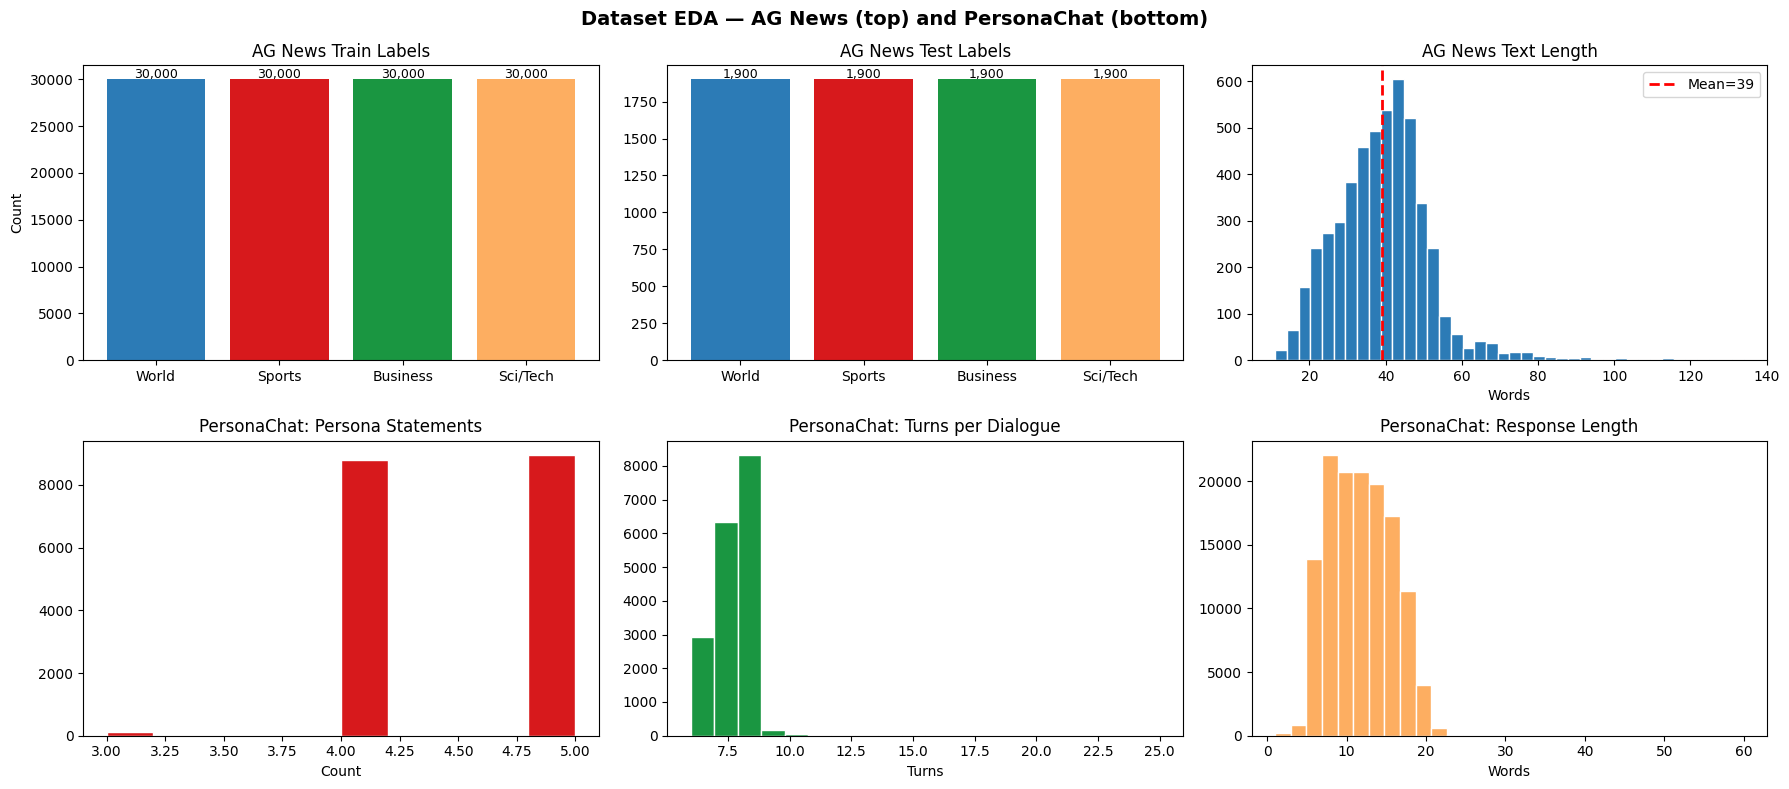

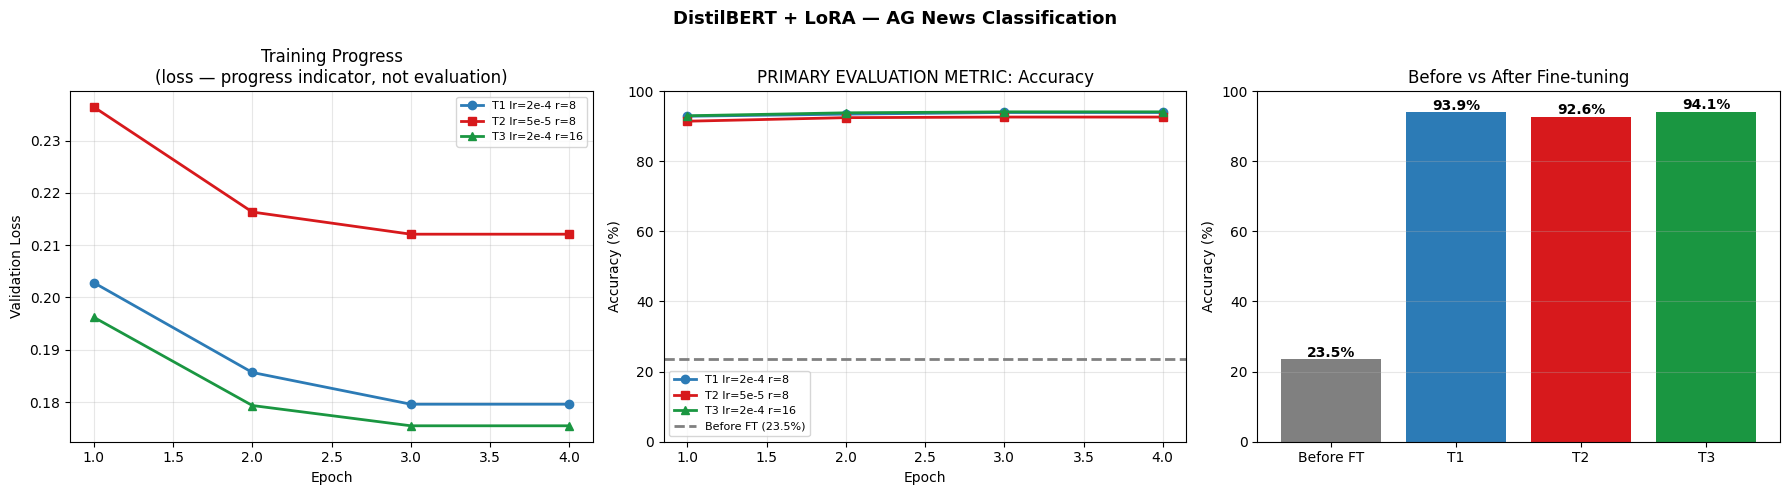

Before: 23.50% | T1: 93.91% | T2: 92.61% | T3: 94.09%


In [ ]:
#  DistilBERT: Results Visualisation
# Dynamic x-axis: computed from actual log length
%matplotlib inline
ep1 = ep_axis(dbert_l1)
ep2 = ep_axis(dbert_l2)
ep3 = ep_axis(dbert_l3)

fig, ax = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('DistilBERT + LoRA — AG News Classification',
             fontsize=13, fontweight='bold')

# Panel 1: Training loss (progress indicator only)
ax[0].plot(ep1, dbert_t1_loss, 'o-', label='T1 lr=2e-4 r=8',  color=C[0], lw=2)
ax[0].plot(ep2, dbert_t2_loss, 's-', label='T2 lr=5e-5 r=8',  color=C[1], lw=2)
ax[0].plot(ep3, dbert_t3_loss, '^-', label='T3 lr=2e-4 r=16', color=C[2], lw=2)
ax[0].set_xlabel('Epoch'); ax[0].set_ylabel('Validation Loss')
ax[0].set_title('Training Progress\n(loss — progress indicator, not evaluation)')
ax[0].legend(fontsize=8); ax[0].grid(alpha=0.3)

# Panel 2: Accuracy per epoch (PRIMARY evaluation metric)
ax[1].plot(ep1, dbert_t1_acc, 'o-', label='T1 lr=2e-4 r=8',  color=C[0], lw=2)
ax[1].plot(ep2, dbert_t2_acc, 's-', label='T2 lr=5e-5 r=8',  color=C[1], lw=2)
ax[1].plot(ep3, dbert_t3_acc, '^-', label='T3 lr=2e-4 r=16', color=C[2], lw=2)
ax[1].axhline(dbert_base_acc, color='gray', ls='--', lw=2,
              label=f'Before FT ({dbert_base_acc:.1f}%)')
ax[1].set_xlabel('Epoch'); ax[1].set_ylabel('Accuracy (%)')
ax[1].set_title('PRIMARY EVALUATION METRIC: Accuracy')
ax[1].legend(fontsize=8); ax[1].set_ylim(0, 100); ax[1].grid(alpha=0.3)

# Panel 3: Before vs After
stages = ['Before FT', 'T1', 'T2', 'T3']
accs   = [dbert_base_acc,
          max(dbert_t1_acc), max(dbert_t2_acc), max(dbert_t3_acc)]
bars = ax[2].bar(stages, accs, color=['gray'] + C[:3])
for b, v in zip(bars, accs):
    ax[2].text(b.get_x() + b.get_width()/2, v + 0.8,
               f'{v:.1f}%', ha='center', fontweight='bold')
ax[2].set_ylabel('Accuracy (%)'); ax[2].set_ylim(0, 100)
ax[2].set_title('Before vs After Fine-tuning')
ax[2].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig('dbert_results.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'Before: {dbert_base_acc:.2f}% | T1: {max(dbert_t1_acc):.2f}% | '
      f'T2: {max(dbert_t2_acc):.2f}% | T3: {max(dbert_t3_acc):.2f}%')

### 1.2 Model 2: roberta-base + LoRA
Encoder-only | 125M parameters | 12 layers | Optimised MLM pre-training (Liu et al., 2019)
LoRA target modules: `query`, `value`

In [ ]:
#  RoBERTa: Tokenise AG News
torch.cuda.empty_cache()
ROBERTA   = 'roberta-base'
rob_tok   = AutoTokenizer.from_pretrained(ROBERTA, add_prefix_space=True)
rob_tr    = tokenize_ag(rob_tok, ag_train)
rob_te    = tokenize_ag(rob_tok, ag_test)
rob_col   = DataCollatorWithPadding(tokenizer=rob_tok)
print(f' RoBERTa — Train: {len(rob_tr):,} | Test: {len(rob_te):,}')

config.json:   0%|          | 0.00/481 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Map:   0%|          | 0/120000 [00:00<?, ? examples/s]

Map:   0%|          | 0/7600 [00:00<?, ? examples/s]

 RoBERTa — Train: 120,000 | Test: 7,600


In [ ]:
#  RoBERTa: Baseline BEFORE fine-tuning
_m = AutoModelForSequenceClassification.from_pretrained(
    ROBERTA, num_labels=NUM_LABELS, ignore_mismatched_sizes=True)
_m.to(device)
rob_base_acc = eval_baseline(_m, rob_te, rob_col) * 100
print(f' RoBERTa BEFORE fine-tuning: {rob_base_acc:.2f}%')
del _m
torch.cuda.empty_cache()

model.safetensors:   0%|          | 0.00/499M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

RobertaForSequenceClassification LOAD REPORT from: roberta-base
Key                             | Status     | 
--------------------------------+------------+-
lm_head.layer_norm.weight       | UNEXPECTED | 
lm_head.bias                    | UNEXPECTED | 
lm_head.dense.bias              | UNEXPECTED | 
lm_head.layer_norm.bias         | UNEXPECTED | 
roberta.embeddings.position_ids | UNEXPECTED | 
lm_head.dense.weight            | UNEXPECTED | 
classifier.dense.bias           | MISSING    | 
classifier.out_proj.weight      | MISSING    | 
classifier.dense.weight         | MISSING    | 
classifier.out_proj.bias        | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


 RoBERTa BEFORE fine-tuning: 25.00%


In [ ]:
#  RoBERTa: LoRA model factory
def make_rob(r=8, alpha=16):
    base = AutoModelForSequenceClassification.from_pretrained(
        ROBERTA, num_labels=NUM_LABELS, ignore_mismatched_sizes=True)
    cfg = LoraConfig(
        task_type=TaskType.SEQ_CLS,
        r=r,
        lora_alpha=alpha,
        lora_dropout=0.1,
        target_modules=['query', 'value'],
        bias='none',
    )
    m = get_peft_model(base, cfg)
    m.print_trainable_parameters()
    return m

In [ ]:
#  RoBERTa Trial 1: lr=2e-4 | batch=16 | epochs=3 | r=8
rob_m1 = make_rob(r=8, alpha=16)
rob_e1, rob_l1 = run_cls_trial(
    rob_m1, rob_tr, rob_te, rob_col, './rt1',
    lr=2e-4, batch=16, epochs=3,
    label='RoBERTa | T1 | lr=2e-4 | batch=16 | epochs=3 | r=8')
rob_t1_acc  = [x['eval_accuracy'] * 100 for x in rob_l1]
rob_t1_loss = [x['eval_loss']           for x in rob_l1]

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

RobertaForSequenceClassification LOAD REPORT from: roberta-base
Key                             | Status     | 
--------------------------------+------------+-
lm_head.layer_norm.weight       | UNEXPECTED | 
lm_head.bias                    | UNEXPECTED | 
lm_head.dense.bias              | UNEXPECTED | 
lm_head.layer_norm.bias         | UNEXPECTED | 
roberta.embeddings.position_ids | UNEXPECTED | 
lm_head.dense.weight            | UNEXPECTED | 
classifier.dense.bias           | MISSING    | 
classifier.out_proj.weight      | MISSING    | 
classifier.dense.weight         | MISSING    | 
classifier.out_proj.bias        | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


trainable params: 888,580 || all params: 125,537,288 || trainable%: 0.7078

 RoBERTa | T1 | lr=2e-4 | batch=16 | epochs=3 | r=8


Epoch,Training Loss,Validation Loss,Accuracy
1,0.221909,0.193326,0.937895
2,0.179663,0.183022,0.942500
3,0.157569,0.178096,0.946184


  Accuracy : 94.62%
   Time    : 26.6 min


In [ ]:
#  RoBERTa Trial 2: lr=5e-5 | batch=16 | epochs=3 | r=8
torch.cuda.empty_cache()
rob_m2 = make_rob(r=8, alpha=16)
rob_e2, rob_l2 = run_cls_trial(
    rob_m2, rob_tr, rob_te, rob_col, './rt2',
    lr=5e-5, batch=16, epochs=3,
    label='RoBERTa | T2 | lr=5e-5 | batch=16 | epochs=3 | r=8')
rob_t2_acc  = [x['eval_accuracy'] * 100 for x in rob_l2]
rob_t2_loss = [x['eval_loss']           for x in rob_l2]

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

RobertaForSequenceClassification LOAD REPORT from: roberta-base
Key                             | Status     | 
--------------------------------+------------+-
lm_head.layer_norm.weight       | UNEXPECTED | 
lm_head.bias                    | UNEXPECTED | 
lm_head.dense.bias              | UNEXPECTED | 
lm_head.layer_norm.bias         | UNEXPECTED | 
roberta.embeddings.position_ids | UNEXPECTED | 
lm_head.dense.weight            | UNEXPECTED | 
classifier.dense.bias           | MISSING    | 
classifier.out_proj.weight      | MISSING    | 
classifier.dense.weight         | MISSING    | 
classifier.out_proj.bias        | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


trainable params: 888,580 || all params: 125,537,288 || trainable%: 0.7078

 RoBERTa | T2 | lr=5e-5 | batch=16 | epochs=3 | r=8


Epoch,Training Loss,Validation Loss,Accuracy
1,0.248764,0.225203,0.928158
2,0.211931,0.206791,0.933158
3,0.195426,0.203241,0.935526


  Accuracy : 93.55%
   Time    : 26.5 min


In [ ]:
#  RoBERTa Trial 3: lr=2e-4 | batch=16 | epochs=3 | r=16
torch.cuda.empty_cache()
rob_m3 = make_rob(r=16, alpha=32)
rob_e3, rob_l3 = run_cls_trial(
    rob_m3, rob_tr, rob_te, rob_col, './rt3',
    lr=2e-4, batch=16, epochs=3,
    label='RoBERTa | T3 | lr=2e-4 | batch=16 | epochs=3 | r=16')
rob_t3_acc  = [x['eval_accuracy'] * 100 for x in rob_l3]
rob_t3_loss = [x['eval_loss']           for x in rob_l3]

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

RobertaForSequenceClassification LOAD REPORT from: roberta-base
Key                             | Status     | 
--------------------------------+------------+-
lm_head.layer_norm.weight       | UNEXPECTED | 
lm_head.bias                    | UNEXPECTED | 
lm_head.dense.bias              | UNEXPECTED | 
lm_head.layer_norm.bias         | UNEXPECTED | 
roberta.embeddings.position_ids | UNEXPECTED | 
lm_head.dense.weight            | UNEXPECTED | 
classifier.dense.bias           | MISSING    | 
classifier.out_proj.weight      | MISSING    | 
classifier.dense.weight         | MISSING    | 
classifier.out_proj.bias        | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


trainable params: 1,183,492 || all params: 125,832,200 || trainable%: 0.9405

 RoBERTa | T3 | lr=2e-4 | batch=16 | epochs=3 | r=16


Epoch,Training Loss,Validation Loss,Accuracy
1,0.222083,0.187612,0.939737
2,0.181237,0.176351,0.944605
3,0.146971,0.174064,0.946974


  Accuracy : 94.70%
   Time    : 26.6 min


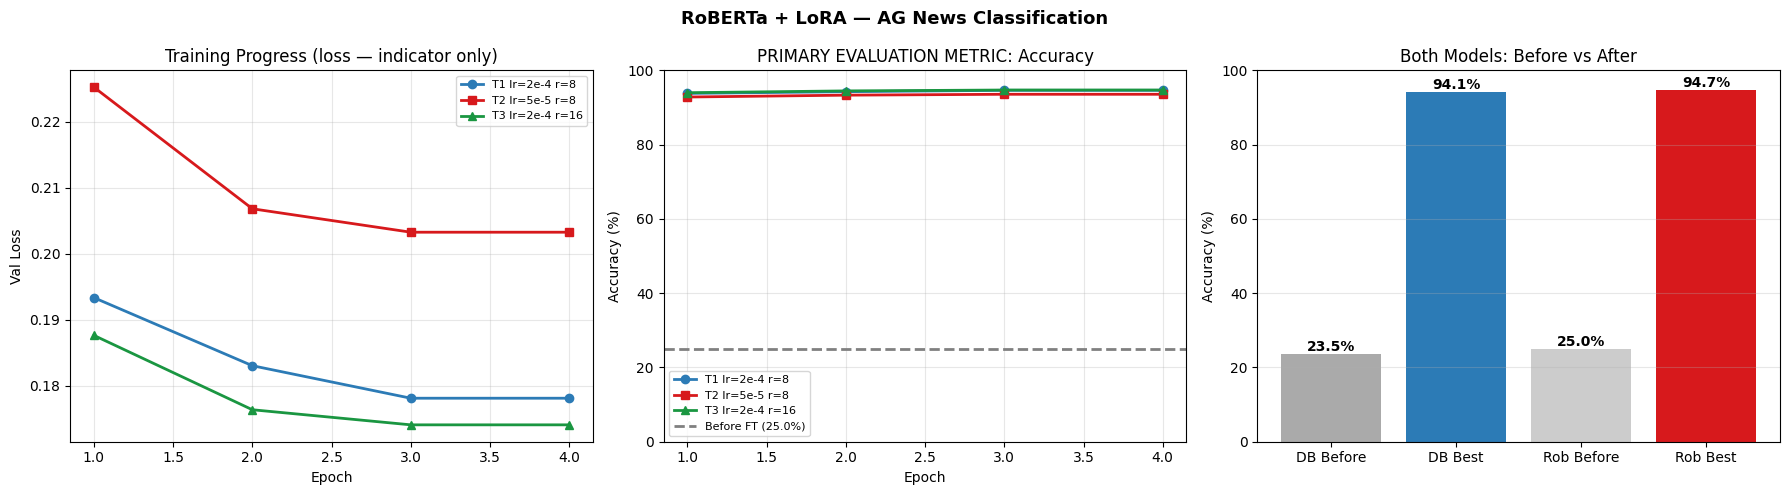

TASK 1 — CLASSIFICATION RESULTS
Primary metric: Accuracy | Loss = training indicator only
     Model     Stage   LR Batch LoRA r Val Accuracy
DistilBERT BEFORE FT    -     -      -       23.50%
DistilBERT   T1 best 2e-4    32    r=8       93.91%
DistilBERT   T2 best 5e-5    32    r=8       92.61%
DistilBERT   T3 best 2e-4    32   r=16       94.09%
   RoBERTa BEFORE FT    -     -      -       25.00%
   RoBERTa   T1 best 2e-4    16    r=8       94.62%
   RoBERTa   T2 best 5e-5    16    r=8       93.55%
   RoBERTa   T3 best 2e-4    16   r=16       94.70%

Best DistilBERT : 94.09%
Best RoBERTa    : 94.70%


In [ ]:
#  RoBERTa: Visualisation + Classification Summary Table
er1 = ep_axis(rob_l1)
er2 = ep_axis(rob_l2)
er3 = ep_axis(rob_l3)

fig, ax = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('RoBERTa + LoRA — AG News Classification',
             fontsize=13, fontweight='bold')

ax[0].plot(er1, rob_t1_loss, 'o-', label='T1 lr=2e-4 r=8',  color=C[0], lw=2)
ax[0].plot(er2, rob_t2_loss, 's-', label='T2 lr=5e-5 r=8',  color=C[1], lw=2)
ax[0].plot(er3, rob_t3_loss, '^-', label='T3 lr=2e-4 r=16', color=C[2], lw=2)
ax[0].set_xlabel('Epoch'); ax[0].set_ylabel('Val Loss')
ax[0].set_title('Training Progress (loss — indicator only)')
ax[0].legend(fontsize=8); ax[0].grid(alpha=0.3)

ax[1].plot(er1, rob_t1_acc, 'o-', label='T1 lr=2e-4 r=8',  color=C[0], lw=2)
ax[1].plot(er2, rob_t2_acc, 's-', label='T2 lr=5e-5 r=8',  color=C[1], lw=2)
ax[1].plot(er3, rob_t3_acc, '^-', label='T3 lr=2e-4 r=16', color=C[2], lw=2)
ax[1].axhline(rob_base_acc, color='gray', ls='--', lw=2,
              label=f'Before FT ({rob_base_acc:.1f}%)')
ax[1].set_xlabel('Epoch'); ax[1].set_ylabel('Accuracy (%)')
ax[1].set_title('PRIMARY EVALUATION METRIC: Accuracy')
ax[1].legend(fontsize=8); ax[1].set_ylim(0, 100); ax[1].grid(alpha=0.3)

bm = ['DB Before', 'DB Best', 'Rob Before', 'Rob Best']
ba = [dbert_base_acc,
      max(max(dbert_t1_acc), max(dbert_t2_acc), max(dbert_t3_acc)),
      rob_base_acc,
      max(max(rob_t1_acc),   max(rob_t2_acc),   max(rob_t3_acc))]
bars = ax[2].bar(bm, ba, color=['#AAA', '#2C7BB6', '#CCC', '#D7191C'])
for b, v in zip(bars, ba):
    ax[2].text(b.get_x() + b.get_width()/2, v + 0.8,
               f'{v:.1f}%', ha='center', fontweight='bold')
ax[2].set_ylabel('Accuracy (%)'); ax[2].set_ylim(0, 100)
ax[2].set_title('Both Models: Before vs After')
ax[2].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig('roberta_results.png', dpi=150, bbox_inches='tight')
plt.show()

# ── Classification Summary Table
print('=' * 65)
print('TASK 1 — CLASSIFICATION RESULTS')
print('Primary metric: Accuracy | Loss = training indicator only')
print('=' * 65)
rows = [
    ['DistilBERT', 'BEFORE FT', '-',    '-',  '-',   f'{dbert_base_acc:.2f}%'],
    ['DistilBERT', 'T1 best',  '2e-4', '32', 'r=8', f'{max(dbert_t1_acc):.2f}%'],
    ['DistilBERT', 'T2 best',  '5e-5', '32', 'r=8', f'{max(dbert_t2_acc):.2f}%'],
    ['DistilBERT', 'T3 best',  '2e-4', '32', 'r=16',f'{max(dbert_t3_acc):.2f}%'],
    ['RoBERTa',   'BEFORE FT', '-',    '-',  '-',   f'{rob_base_acc:.2f}%'],
    ['RoBERTa',   'T1 best',  '2e-4', '16', 'r=8', f'{max(rob_t1_acc):.2f}%'],
    ['RoBERTa',   'T2 best',  '5e-5', '16', 'r=8', f'{max(rob_t2_acc):.2f}%'],
    ['RoBERTa',   'T3 best',  '2e-4', '16', 'r=16',f'{max(rob_t3_acc):.2f}%'],
]
df = pd.DataFrame(rows,
    columns=['Model', 'Stage', 'LR', 'Batch', 'LoRA r', 'Val Accuracy'])
print(df.to_string(index=False))
print(f'\nBest DistilBERT : {max(max(dbert_t1_acc),max(dbert_t2_acc),max(dbert_t3_acc)):.2f}%')
print(f'Best RoBERTa    : {max(max(rob_t1_acc),max(rob_t2_acc),max(rob_t3_acc)):.2f}%')

---
## Section 2 — Task 2: PersonaChat Dialogue Generation

**Models:**
- `gpt2` — decoder-only, 117M params, CLM pre-training on WebText
- `microsoft/DialoGPT-small` — decoder-only, 117M params, CLM on 147M Reddit dialogues

**Primary evaluation metric: BLEU-4** | Perplexity = secondary | Loss = training indicator

In [ ]:
#  Build PersonaChat text sequences
torch.cuda.empty_cache()
train_texts = build_persona_texts(pc_train)
valid_texts = build_persona_texts(pc_valid)
print(f' Train sequences : {len(train_texts):,}')
print(f' Valid sequences : {len(valid_texts):,}')
print('Example:', train_texts[0][:200], '...')

 Train sequences : 131,438
 Valid sequences : 7,801
Example: [PERSONA] i like to remodel homes . i like to go hunting . i like to shoot a bow . my favorite holiday is halloween . [CONTEXT] hi , how are you doing ? i'm getting ready to do some cheetah chasing to ...


### 2.1 Model 3: gpt2 + LoRA
Decoder-only | 117M parameters | 12 layers | CLM pre-training
LoRA target module: `c_attn` (combined QKV projection)

In [ ]:
#  GPT-2: Tokenise PersonaChat
GPT2     = 'gpt2'
gpt2_tok = AutoTokenizer.from_pretrained(GPT2)
gpt2_tok.pad_token = gpt2_tok.eos_token
gpt2_tr  = tokenize_gen(gpt2_tok, train_texts)
gpt2_va  = tokenize_gen(gpt2_tok, valid_texts)
gpt2_col = DataCollatorForLanguageModeling(tokenizer=gpt2_tok, mlm=False)
print(f' GPT-2 — train: {len(gpt2_tr):,} | valid: {len(gpt2_va):,}')

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Map:   0%|          | 0/131438 [00:00<?, ? examples/s]

Map:   0%|          | 0/7801 [00:00<?, ? examples/s]

 GPT-2 — train: 131,438 | valid: 7,801


In [ ]:
#  GPT-2: Baseline BEFORE fine-tuning
print('Computing GPT-2 baseline BEFORE fine-tuning...')
_m = AutoModelForCausalLM.from_pretrained(GPT2).to(device)
gpt2_base_ppl  = compute_ppl(_m,    gpt2_tok, valid_texts)
gpt2_base_bleu = compute_bleu4(_m,  gpt2_tok, valid_texts)
print(f' GPT-2 BEFORE FT — PPL: {gpt2_base_ppl} | BLEU-4: {gpt2_base_bleu}')
del _m
torch.cuda.empty_cache()

Computing GPT-2 baseline BEFORE fine-tuning...


model.safetensors:   0%|          | 0.00/548M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

GPT2LMHeadModel LOAD REPORT from: gpt2
Key                  | Status     |  | 
---------------------+------------+--+-
h.{0...11}.attn.bias | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

`loss_type=None` was set in the config but it is unrecognized. Using the default loss: `ForCausalLMLoss`.


 GPT-2 BEFORE FT — PPL: 43.92 | BLEU-4: 0.92


In [ ]:
#  GPT-2: LoRA model factory
def make_gpt2(r=8, alpha=16):
    base = AutoModelForCausalLM.from_pretrained(GPT2)
    cfg  = LoraConfig(
        task_type=TaskType.CAUSAL_LM,
        r=r,
        lora_alpha=alpha,
        lora_dropout=0.1,
        target_modules=['c_attn'],
        bias='none',
    )
    m = get_peft_model(base, cfg)
    m.print_trainable_parameters()
    return m

In [ ]:
#  GPT-2 Trial 1: lr=2e-4 | batch=4 | epochs=2 | r=8
gpt2_m1 = make_gpt2(r=8, alpha=16)
gpt2_e1, gpt2_l1 = run_gen_trial(
    gpt2_m1, gpt2_tr, gpt2_va, gpt2_col, './g1',
    lr=2e-4, batch=4, epochs=2,
    label='GPT-2 | T1 | lr=2e-4 | batch=4 | epochs=2 | r=8')
gpt2_t1_loss = [x['eval_loss']           for x in gpt2_l1]
gpt2_t1_ppl  = [math.exp(x['eval_loss']) for x in gpt2_l1]
gpt2_t1_bleu = compute_bleu4(gpt2_m1, gpt2_tok, valid_texts)
print(f' GPT-2 T1 — BLEU-4: {gpt2_t1_bleu} | PPL: {gpt2_t1_ppl[-1]:.1f}')

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

GPT2LMHeadModel LOAD REPORT from: gpt2
Key                  | Status     |  | 
---------------------+------------+--+-
h.{0...11}.attn.bias | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


trainable params: 294,912 || all params: 124,734,720 || trainable%: 0.2364

 GPT-2 | T1 | lr=2e-4 | batch=4 | epochs=2 | r=8


Epoch,Training Loss,Validation Loss
1,2.460456,2.523851
2,2.418300,2.527225


  Perplexity : 12.5
    Time      : 65.2 min
 GPT-2 T1 — BLEU-4: 1.53 | PPL: 12.5


In [ ]:
#  GPT-2 Trial 2: lr=5e-5 | batch=8 | epochs=2 | r=8
torch.cuda.empty_cache()
gpt2_m2 = make_gpt2(r=8, alpha=16)
gpt2_e2, gpt2_l2 = run_gen_trial(
    gpt2_m2, gpt2_tr, gpt2_va, gpt2_col, './g2',
    lr=5e-5, batch=8, epochs=2,
    label='GPT-2 | T2 | lr=5e-5 | batch=8 | epochs=2 | r=8')
gpt2_t2_loss = [x['eval_loss']           for x in gpt2_l2]
gpt2_t2_ppl  = [math.exp(x['eval_loss']) for x in gpt2_l2]
gpt2_t2_bleu = compute_bleu4(gpt2_m2, gpt2_tok, valid_texts)
print(f' GPT-2 T2 — BLEU-4: {gpt2_t2_bleu} | PPL: {gpt2_t2_ppl[-1]:.1f}')

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

GPT2LMHeadModel LOAD REPORT from: gpt2
Key                  | Status     |  | 
---------------------+------------+--+-
h.{0...11}.attn.bias | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


trainable params: 294,912 || all params: 124,734,720 || trainable%: 0.2364

 GPT-2 | T2 | lr=5e-5 | batch=8 | epochs=2 | r=8


Epoch,Training Loss,Validation Loss
1,2.619461,2.558446
2,2.593501,2.547314


  Perplexity : 12.8
    Time      : 53.4 min
 GPT-2 T2 — BLEU-4: 1.54 | PPL: 12.8


In [ ]:
# ── GPT-2 Trial 3: lr=2e-4 | batch=8 | epochs=3 | r=16
torch.cuda.empty_cache()
gpt2_m3 = make_gpt2(r=16, alpha=32)
gpt2_e3, gpt2_l3 = run_gen_trial(
    gpt2_m3, gpt2_tr, gpt2_va, gpt2_col, './g3',
    lr=2e-4, batch=8, epochs=3,
    label='GPT-2 | T3 | lr=2e-4 | batch=8 | epochs=3 | r=16')
gpt2_t3_loss = [x['eval_loss']           for x in gpt2_l3]
gpt2_t3_ppl  = [math.exp(x['eval_loss']) for x in gpt2_l3]
gpt2_t3_bleu = compute_bleu4(gpt2_m3, gpt2_tok, valid_texts)
print(f' GPT-2 T3 — BLEU-4: {gpt2_t3_bleu} | PPL: {gpt2_t3_ppl[-1]:.1f}')

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

GPT2LMHeadModel LOAD REPORT from: gpt2
Key                  | Status     |  | 
---------------------+------------+--+-
h.{0...11}.attn.bias | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


trainable params: 589,824 || all params: 125,029,632 || trainable%: 0.4717

 GPT-2 | T3 | lr=2e-4 | batch=8 | epochs=3 | r=16


Epoch,Training Loss,Validation Loss
1,2.408209,2.536092
2,2.315993,2.577924
3,2.280326,2.594339


  Perplexity : 12.6
    Time      : 80.1 min
 GPT-2 T3 — BLEU-4: 1.5 | PPL: 12.6


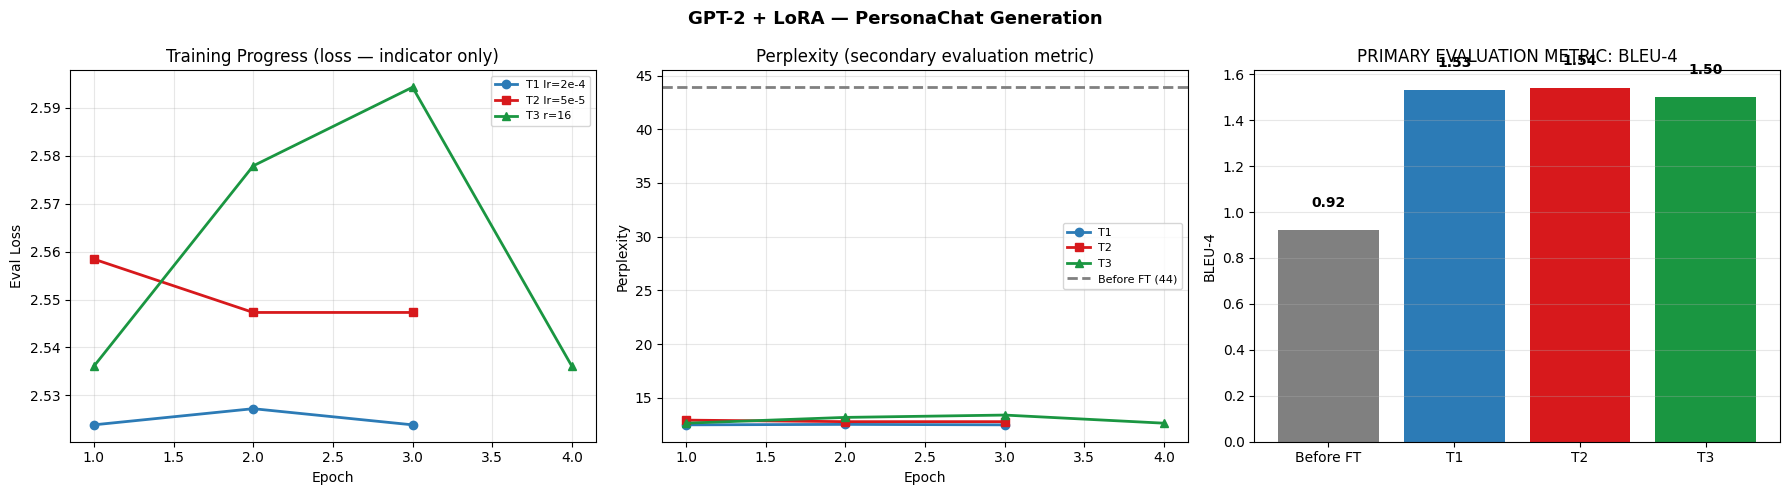

In [ ]:
#  GPT-2: Visualisation
eg1 = ep_axis(gpt2_l1)
eg2 = ep_axis(gpt2_l2)
eg3 = ep_axis(gpt2_l3)

fig, ax = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('GPT-2 + LoRA — PersonaChat Generation',
             fontsize=13, fontweight='bold')

ax[0].plot(eg1, gpt2_t1_loss, 'o-', label='T1 lr=2e-4', color=C[0], lw=2)
ax[0].plot(eg2, gpt2_t2_loss, 's-', label='T2 lr=5e-5', color=C[1], lw=2)
ax[0].plot(eg3, gpt2_t3_loss, '^-', label='T3 r=16',    color=C[2], lw=2)
ax[0].set_xlabel('Epoch'); ax[0].set_ylabel('Eval Loss')
ax[0].set_title('Training Progress (loss — indicator only)')
ax[0].legend(fontsize=8); ax[0].grid(alpha=0.3)

ax[1].plot(eg1, gpt2_t1_ppl, 'o-', label='T1', color=C[0], lw=2)
ax[1].plot(eg2, gpt2_t2_ppl, 's-', label='T2', color=C[1], lw=2)
ax[1].plot(eg3, gpt2_t3_ppl, '^-', label='T3', color=C[2], lw=2)
ax[1].axhline(gpt2_base_ppl, color='gray', ls='--', lw=2,
              label=f'Before FT ({gpt2_base_ppl:.0f})')
ax[1].set_xlabel('Epoch'); ax[1].set_ylabel('Perplexity')
ax[1].set_title('Perplexity (secondary evaluation metric)')
ax[1].legend(fontsize=8); ax[1].grid(alpha=0.3)

bv = [gpt2_base_bleu, gpt2_t1_bleu, gpt2_t2_bleu, gpt2_t3_bleu]
bars = ax[2].bar(['Before FT','T1','T2','T3'], bv, color=['gray']+C[:3])
for b, v in zip(bars, bv):
    ax[2].text(b.get_x()+b.get_width()/2, v+0.1,
               f'{v:.2f}', ha='center', fontweight='bold')
ax[2].set_ylabel('BLEU-4')
ax[2].set_title('PRIMARY EVALUATION METRIC: BLEU-4')
ax[2].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig('gpt2_results.png', dpi=150, bbox_inches='tight')
plt.show()

### 2.2 Model 4: microsoft/DialoGPT-small + LoRA
Decoder-only | 117M parameters | GPT-2 architecture | CLM pre-training on Reddit dialogues
LoRA target module: c_attn

In [ ]:
#  DialoGPT: Tokenise PersonaChat
torch.cuda.empty_cache()
DGPT     = 'microsoft/DialoGPT-small'
dgpt_tok = AutoTokenizer.from_pretrained(DGPT)
dgpt_tok.pad_token = dgpt_tok.eos_token
dgpt_tr  = tokenize_gen(dgpt_tok, train_texts)
dgpt_va  = tokenize_gen(dgpt_tok, valid_texts)
dgpt_col = DataCollatorForLanguageModeling(tokenizer=dgpt_tok, mlm=False)
print(f' DialoGPT — train: {len(dgpt_tr):,} | valid: {len(dgpt_va):,}')

config.json:   0%|          | 0.00/641 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/614 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

Map:   0%|          | 0/131438 [00:00<?, ? examples/s]

Map:   0%|          | 0/7801 [00:00<?, ? examples/s]

 DialoGPT — train: 131,438 | valid: 7,801


In [ ]:
#  DialoGPT: Baseline BEFORE fine-tuning
print('Computing DialoGPT baseline BEFORE fine-tuning...')
_m = AutoModelForCausalLM.from_pretrained(DGPT).to(device)
dgpt_base_ppl  = compute_ppl(_m,   dgpt_tok, valid_texts)
dgpt_base_bleu = compute_bleu4(_m, dgpt_tok, valid_texts)
print(f' DialoGPT BEFORE FT — PPL: {dgpt_base_ppl} | BLEU-4: {dgpt_base_bleu}')
del _m
torch.cuda.empty_cache()

Computing DialoGPT baseline BEFORE fine-tuning...


model.safetensors:   0%|          | 0.00/351M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/149 [00:00<?, ?it/s]

The tied weights mapping and config for this model specifies to tie transformer.wte.weight to lm_head.weight, but both are present in the checkpoints, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning
GPT2LMHeadModel LOAD REPORT from: microsoft/DialoGPT-small
Key                              | Status     |  | 
---------------------------------+------------+--+-
transformer.h.{0...11}.attn.bias | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

 DialoGPT BEFORE FT — PPL: 4203.79 | BLEU-4: 0


In [ ]:
# DialoGPT: LoRA model factory
def make_dgpt(r=8, alpha=16):
    base = AutoModelForCausalLM.from_pretrained(DGPT)
    cfg  = LoraConfig(
        task_type=TaskType.CAUSAL_LM,
        r=r,
        lora_alpha=alpha,
        lora_dropout=0.1,
        target_modules=['c_attn'],
        bias='none',
    )
    m = get_peft_model(base, cfg)
    m.print_trainable_parameters()
    return m

In [ ]:
# DialoGPT Trial 1: lr=2e-4 | batch=8 | epochs=1 | r=8
dgpt_m1 = make_dgpt(r=8, alpha=16)
dgpt_e1, dgpt_l1 = run_gen_trial(
    dgpt_m1, dgpt_tr, dgpt_va, dgpt_col, './d1',
    lr=2e-4, batch=8, epochs=1,
    label='DialoGPT | T1 | lr=2e-4 | batch=8 | epochs=1 | r=8')
dgpt_t1_loss = [x['eval_loss']           for x in dgpt_l1]
dgpt_t1_ppl  = [math.exp(x['eval_loss']) for x in dgpt_l1]
dgpt_t1_bleu = compute_bleu4(dgpt_m1, dgpt_tok, valid_texts)
print(f' DialoGPT T1 — BLEU-4: {dgpt_t1_bleu} | PPL: {dgpt_t1_ppl[-1]:.1f}')

Loading weights:   0%|          | 0/149 [00:00<?, ?it/s]

The tied weights mapping and config for this model specifies to tie transformer.wte.weight to lm_head.weight, but both are present in the checkpoints, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning
GPT2LMHeadModel LOAD REPORT from: microsoft/DialoGPT-small
Key                              | Status     |  | 
---------------------------------+------------+--+-
transformer.h.{0...11}.attn.bias | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


trainable params: 294,912 || all params: 163,332,096 || trainable%: 0.1806

 DialoGPT | T1 | lr=2e-4 | batch=8 | epochs=1 | r=8


Epoch,Training Loss,Validation Loss
1,2.559938,2.476497


  ✅ Perplexity : 11.9
  ⏱  Time      : 26.3 min
✅ DialoGPT T1 — BLEU-4: 1.06 | PPL: 11.9


In [ ]:
# DialoGPT Trial 2: lr=5e-5 | batch=8 | epochs=1 | r=8
torch.cuda.empty_cache()
dgpt_m2 = make_dgpt(r=8, alpha=16)
dgpt_e2, dgpt_l2 = run_gen_trial(
    dgpt_m2, dgpt_tr, dgpt_va, dgpt_col, './d2',
    lr=5e-5, batch=8, epochs=1,
    label='DialoGPT | T2 | lr=5e-5 | batch=8 | epochs=1 | r=8')
dgpt_t2_loss = [x['eval_loss']           for x in dgpt_l2]
dgpt_t2_ppl  = [math.exp(x['eval_loss']) for x in dgpt_l2]
dgpt_t2_bleu = compute_bleu4(dgpt_m2, dgpt_tok, valid_texts)
print(f' DialoGPT T2 — BLEU-4: {dgpt_t2_bleu} | PPL: {dgpt_t2_ppl[-1]:.1f}')

Loading weights:   0%|          | 0/149 [00:00<?, ?it/s]

The tied weights mapping and config for this model specifies to tie transformer.wte.weight to lm_head.weight, but both are present in the checkpoints, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning
GPT2LMHeadModel LOAD REPORT from: microsoft/DialoGPT-small
Key                              | Status     |  | 
---------------------------------+------------+--+-
transformer.h.{0...11}.attn.bias | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


trainable params: 294,912 || all params: 163,332,096 || trainable%: 0.1806

 DialoGPT | T2 | lr=5e-5 | batch=8 | epochs=1 | r=8


Epoch,Training Loss,Validation Loss
1,2.726083,2.535732


  ✅ Perplexity : 12.6
  ⏱  Time      : 26.1 min
✅ DialoGPT T2 — BLEU-4: 0.69 | PPL: 12.6


In [ ]:
# DialoGPT Trial 3: lr=2e-4 | batch=8 | epochs=1 | r=16
torch.cuda.empty_cache()
dgpt_m3 = make_dgpt(r=16, alpha=32)
dgpt_e3, dgpt_l3 = run_gen_trial(
    dgpt_m3, dgpt_tr, dgpt_va, dgpt_col, './d3',
    lr=2e-4, batch=8, epochs=1,
    label='DialoGPT | T3 | lr=2e-4 | batch=8 | epochs=1 | r=16')
dgpt_t3_loss = [x['eval_loss']           for x in dgpt_l3]
dgpt_t3_ppl  = [math.exp(x['eval_loss']) for x in dgpt_l3]
dgpt_t3_bleu = compute_bleu4(dgpt_m3, dgpt_tok, valid_texts)
print(f' DialoGPT T3 — BLEU-4: {dgpt_t3_bleu} | PPL: {dgpt_t3_ppl[-1]:.1f}')

Loading weights:   0%|          | 0/149 [00:00<?, ?it/s]

The tied weights mapping and config for this model specifies to tie transformer.wte.weight to lm_head.weight, but both are present in the checkpoints, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning
GPT2LMHeadModel LOAD REPORT from: microsoft/DialoGPT-small
Key                              | Status     |  | 
---------------------------------+------------+--+-
transformer.h.{0...11}.attn.bias | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


trainable params: 589,824 || all params: 163,627,008 || trainable%: 0.3605

 DialoGPT | T3 | lr=2e-4 | batch=8 | epochs=1 | r=16


Epoch,Training Loss,Validation Loss
1,2.495374,2.468022


  ✅ Perplexity : 11.8
  ⏱  Time      : 26.1 min
✅ DialoGPT T3 — BLEU-4: 0.63 | PPL: 11.8


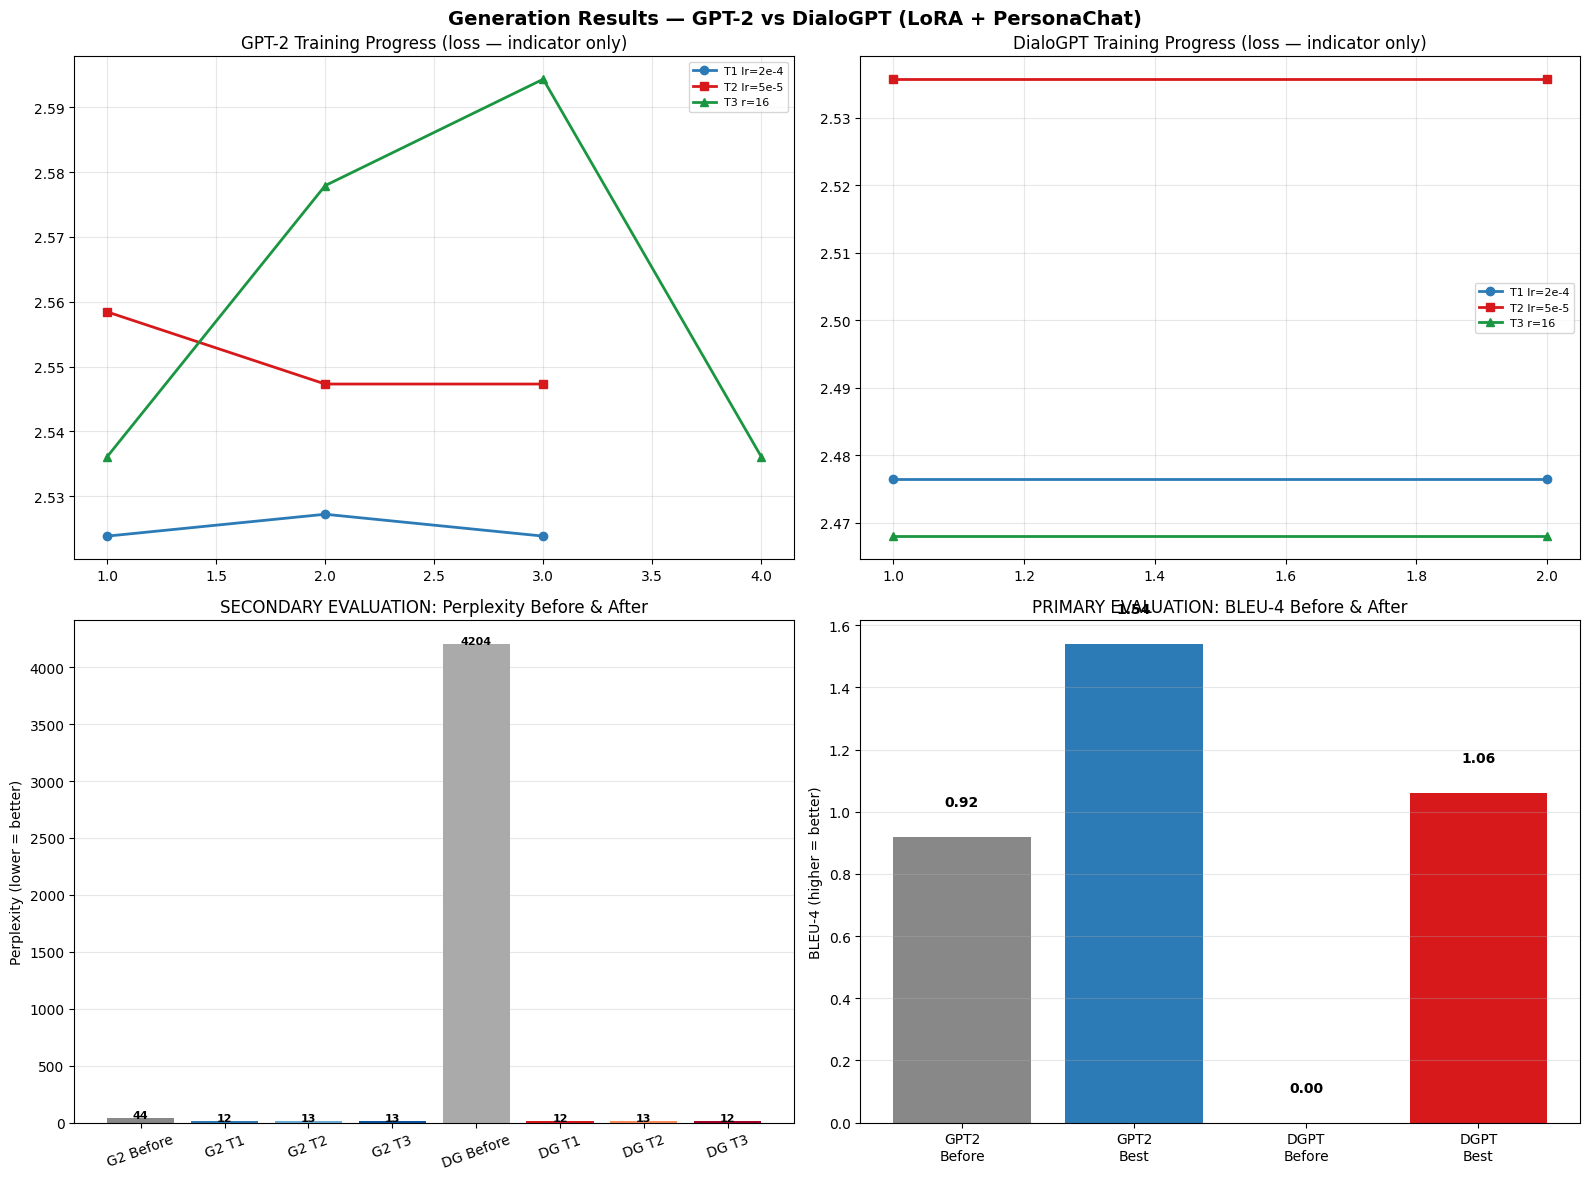

In [ ]:
# Generation: Full Comparison Visualisation
ed1 = ep_axis(dgpt_l1)
ed2 = ep_axis(dgpt_l2)
ed3 = ep_axis(dgpt_l3)

fig, ax = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle('Generation Results — GPT-2 vs DialoGPT (LoRA + PersonaChat)',
             fontsize=14, fontweight='bold')

# GPT-2 loss
ax[0,0].plot(eg1, gpt2_t1_loss, 'o-', label='T1 lr=2e-4', color=C[0], lw=2)
ax[0,0].plot(eg2, gpt2_t2_loss, 's-', label='T2 lr=5e-5', color=C[1], lw=2)
ax[0,0].plot(eg3, gpt2_t3_loss, '^-', label='T3 r=16',    color=C[2], lw=2)
ax[0,0].set_title('GPT-2 Training Progress (loss — indicator only)')
ax[0,0].legend(fontsize=8); ax[0,0].grid(alpha=0.3)

# DialoGPT loss
ax[0,1].plot(ed1, dgpt_t1_loss, 'o-', label='T1 lr=2e-4', color=C[0], lw=2)
ax[0,1].plot(ed2, dgpt_t2_loss, 's-', label='T2 lr=5e-5', color=C[1], lw=2)
ax[0,1].plot(ed3, dgpt_t3_loss, '^-', label='T3 r=16',    color=C[2], lw=2)
ax[0,1].set_title('DialoGPT Training Progress (loss — indicator only)')
ax[0,1].legend(fontsize=8); ax[0,1].grid(alpha=0.3)

# Perplexity (secondary)
gm = ['G2 Before','G2 T1','G2 T2','G2 T3',
      'DG Before','DG T1','DG T2','DG T3']
pv = [gpt2_base_ppl, gpt2_t1_ppl[-1], gpt2_t2_ppl[-1], gpt2_t3_ppl[-1],
      dgpt_base_ppl, dgpt_t1_ppl[-1], dgpt_t2_ppl[-1], dgpt_t3_ppl[-1]]
gc = ['#888','#2C7BB6','#6BAED6','#08519C',
      '#AAA','#D7191C','#FC8D59','#A50026']
bars = ax[1,0].bar(gm, pv, color=gc)
for b, v in zip(bars, pv):
    ax[1,0].text(b.get_x()+b.get_width()/2, v+0.5,
                 f'{v:.0f}', ha='center', fontsize=8, fontweight='bold')
ax[1,0].set_ylabel('Perplexity (lower = better)')
ax[1,0].set_title('SECONDARY EVALUATION: Perplexity Before & After')
ax[1,0].tick_params(axis='x', rotation=20)
ax[1,0].grid(axis='y', alpha=0.3)

# BLEU-4 (primary)
bm2 = ['GPT2\nBefore','GPT2\nBest','DGPT\nBefore','DGPT\nBest']
bv2  = [gpt2_base_bleu,
        max(gpt2_t1_bleu, gpt2_t2_bleu, gpt2_t3_bleu),
        dgpt_base_bleu,
        max(dgpt_t1_bleu, dgpt_t2_bleu, dgpt_t3_bleu)]
bars2 = ax[1,1].bar(bm2, bv2,
                    color=['#888','#2C7BB6','#AAA','#D7191C'])
for b, v in zip(bars2, bv2):
    ax[1,1].text(b.get_x()+b.get_width()/2, v+0.1,
                 f'{v:.2f}', ha='center', fontweight='bold')
ax[1,1].set_ylabel('BLEU-4 (higher = better)')
ax[1,1].set_title('PRIMARY EVALUATION: BLEU-4 Before & After')
ax[1,1].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig('generation_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

In [ ]:
# Before vs After: Qualitative Examples
print('=' * 65)
print('BEFORE vs AFTER — DialoGPT-small Qualitative Examples')
print('=' * 65)
_chk = AutoModelForCausalLM.from_pretrained(DGPT).to(device)
for idx in [0, 4, 10, 18]:
    t = valid_texts[idx]
    if '[RESPONSE]' not in t:
        continue
    ctx, ref = t.split('[RESPONSE]', 1)
    enc = dgpt_tok(
        ctx + '[RESPONSE]',
        return_tensors='pt',
        truncation=True,
        max_length=160,
    ).to(device)
    with torch.no_grad():
        ob = _chk.generate(
            **enc, max_new_tokens=40, do_sample=True,
            temperature=0.8, top_p=0.9,
            pad_token_id=dgpt_tok.eos_token_id)
        oa = dgpt_m3.generate(
            **enc, max_new_tokens=40, do_sample=True,
            temperature=0.8, top_p=0.9,
            pad_token_id=dgpt_tok.eos_token_id)
    n = enc['input_ids'].shape[1]
    before = dgpt_tok.decode(
        ob[0][n:], skip_special_tokens=True).strip()
    after  = dgpt_tok.decode(
        oa[0][n:], skip_special_tokens=True).strip()
    print(f'\n[Example {idx+1}]')
    print(f'  Gold      : {ref.strip()[:90]}')
    print(f'  Before FT : {before[:90]}')
    print(f'  After FT  : {after[:90]}')
del _chk
torch.cuda.empty_cache()

BEFORE vs AFTER — DialoGPT-small Qualitative Examples


Loading weights:   0%|          | 0/149 [00:00<?, ?it/s]

The tied weights mapping and config for this model specifies to tie transformer.wte.weight to lm_head.weight, but both are present in the checkpoints, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning
GPT2LMHeadModel LOAD REPORT from: microsoft/DialoGPT-small
Key                              | Status     |  | 
---------------------------------+------------+--+-
transformer.h.{0...11}.attn.bias | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.



[Example 1]
  Gold      : i am good , i just got off work and tired , i have two jobs .
  Before FT : 
  After FT  : hello. just doing my first day of work for a real estate agent. how about you? | i am good

[Example 5]
  Gold      : yes it is neat , i stunt double , it is so much fun and hard work .
  Before FT : 
  After FT  : i love being a stunt double in the theatre. i read twenty books a year. how are you?!?!!!!

[Example 11]
  Gold      : good for you . do you like vintage cars ? i've two older mustangs .
  Before FT : 
  After FT  : wow, that sounds like a lot of work. i love the outdoors. do you have a favorite kind of m

[Example 19]
  Gold      : man your lucky i am a baby delivery nurse and the pay sucks
  Before FT : 
  After FT  : do you have a favorite song? i love country. do you have any pets? i love my dog. i love h


In [ ]:
# Generation Summary Table
print('=' * 65)
print('TASK 2 — GENERATION RESULTS')
print('Primary: BLEU-4 | Secondary: Perplexity | Loss = indicator only')
print('=' * 65)
rows = [
    ['GPT-2','BEFORE FT','-',    '-','- ',f'{gpt2_base_ppl:.1f}',f'{gpt2_base_bleu:.2f}'],
    ['GPT-2','T1',       '2e-4','4','r=8', f'{gpt2_t1_ppl[-1]:.1f}',f'{gpt2_t1_bleu:.2f}'],
    ['GPT-2','T2',       '5e-5','4','r=8', f'{gpt2_t2_ppl[-1]:.1f}',f'{gpt2_t2_bleu:.2f}'],
    ['GPT-2','T3',       '2e-4','4','r=16',f'{gpt2_t3_ppl[-1]:.1f}',f'{gpt2_t3_bleu:.2f}'],
    ['DialoGPT','BEFORE FT','-','-','- ',f'{dgpt_base_ppl:.1f}',f'{dgpt_base_bleu:.2f}'],
    ['DialoGPT','T1',    '2e-4','4','r=8', f'{dgpt_t1_ppl[-1]:.1f}',f'{dgpt_t1_bleu:.2f}'],
    ['DialoGPT','T2',    '5e-5','4','r=8', f'{dgpt_t2_ppl[-1]:.1f}',f'{dgpt_t2_bleu:.2f}'],
    ['DialoGPT','T3',    '2e-4','4','r=16',f'{dgpt_t3_ppl[-1]:.1f}',f'{dgpt_t3_bleu:.2f}'],
]
df2 = pd.DataFrame(
    rows, columns=['Model','Stage','LR','Batch','LoRA r','PPL','BLEU-4'])
print(df2.to_string(index=False))

TASK 2 — GENERATION RESULTS
Primary: BLEU-4 | Secondary: Perplexity | Loss = indicator only
   Model     Stage   LR Batch LoRA r    PPL BLEU-4
   GPT-2 BEFORE FT    -     -     -    43.9   0.92
   GPT-2        T1 2e-4     4    r=8   12.5   1.53
   GPT-2        T2 5e-5     4    r=8   12.8   1.54
   GPT-2        T3 2e-4     4   r=16   12.6   1.50
DialoGPT BEFORE FT    -     -     -  4203.8   0.00
DialoGPT        T1 2e-4     4    r=8   11.9   1.06
DialoGPT        T2 5e-5     4    r=8   12.6   0.69
DialoGPT        T3 2e-4     4   r=16   11.8   0.63


In [ ]:
# FINAL COMPLETE SUMMARY
best_db = max(max(dbert_t1_acc), max(dbert_t2_acc), max(dbert_t3_acc))
best_rb = max(max(rob_t1_acc),   max(rob_t2_acc),   max(rob_t3_acc))
best_gp = min(gpt2_t1_ppl[-1],  gpt2_t2_ppl[-1],   gpt2_t3_ppl[-1])
best_dp = min(dgpt_t1_ppl[-1],  dgpt_t2_ppl[-1],   dgpt_t3_ppl[-1])
best_gb = max(gpt2_t1_bleu,     gpt2_t2_bleu,       gpt2_t3_bleu)
best_d2 = max(dgpt_t1_bleu,     dgpt_t2_bleu,       dgpt_t3_bleu)

print('=' * 65)
print('ASSIGNMENT 3 — COMPLETE RESULTS SUMMARY')
print('=' * 65)
print()
print('TASK 1: CLASSIFICATION (Primary evaluation metric: Accuracy)')
print(f'  DistilBERT  Before: {dbert_base_acc:.1f}%  After: {best_db:.1f}%'
      f'  Improvement: +{best_db - dbert_base_acc:.1f} pp')
print(f'  RoBERTa     Before: {rob_base_acc:.1f}%  After: {best_rb:.1f}%'
      f'  Improvement: +{best_rb - rob_base_acc:.1f} pp')
print()
print('TASK 2: GENERATION (Primary: BLEU-4 | Secondary: Perplexity)')
print(f'  GPT-2       PPL: {gpt2_base_ppl:.0f} → {best_gp:.0f}'
      f'  BLEU-4: {gpt2_base_bleu:.2f} → {best_gb:.2f}')
print(f'  DialoGPT    PPL: {dgpt_base_ppl:.0f} → {best_dp:.0f}'
      f'  BLEU-4: {dgpt_base_bleu:.2f} → {best_d2:.2f}')
print()
print('Plots saved:')
print('  dataset_eda.png')
print('  dbert_results.png')
print('  roberta_results.png')
print('  gpt2_results.png')
print('  generation_comparison.png')

ASSIGNMENT 3 — COMPLETE RESULTS SUMMARY

TASK 1: CLASSIFICATION (Primary evaluation metric: Accuracy)
  DistilBERT  Before: 23.5%  After: 94.1%  Improvement: +70.6 pp
  RoBERTa     Before: 25.0%  After: 94.7%  Improvement: +69.7 pp

TASK 2: GENERATION (Primary: BLEU-4 | Secondary: Perplexity)
  GPT-2       PPL: 44 → 12  BLEU-4: 0.92 → 1.54
  DialoGPT    PPL: 4204 → 12  BLEU-4: 0.00 → 1.06

Plots saved:
  dataset_eda.png
  dbert_results.png
  roberta_results.png
  gpt2_results.png
  generation_comparison.png


In [ ]:
from google.colab import files

# Download all figures
files.download('dataset_eda.png')
files.download('dbert_results.png')
files.download('roberta_results.png')
files.download('gpt2_results.png')
files.download('generation_comparison.png')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>